<div style="display:block; width:100%; box-sizing:border-box; margin:12px 0; padding:40px; text-align:center; border-radius:18px;
            color:#eaffea; border:2px solid #39ff14;
            background:radial-gradient(circle at 50% 0%, #0b2a0b 0%, #020802 70%);
            text-shadow:0 0 8px #39ff14, 0 0 22px #39ff14;
            box-shadow:0 0 20px #39ff1499, inset 0 0 25px #39ff1455, 0 4px 18px rgba(0,0,0,0.35);">
  <div style="font-size:38px; font-weight:bold; letter-spacing:3px;">
    Rice Image Classification 🌾
  </div>
  <div style="font-size:18px; margin-top:12px; opacity:0.85;">
    Multi-Class CNN with Keras
  </div>
</div>

<div style="background:#0b2a0b; color:#eaffea; padding:20px; text-align:center;
            font-size:30px; border-radius: 0 60px 0 60px; border:2px solid #39ff14;">
  Import Libraries 📚
</div>

In [1]:
import pandas as pd
import numpy as np
from sklearn.metrics import confusion_matrix, classification_report
import matplotlib.pyplot as plt
import seaborn as sns
import os
from google.colab import files
import torch
import torch.nn as nn
from torch.utils.data import DataLoader,Dataset
import torchvision.transforms as transforms
from torchvision.datasets import ImageFolder
import torch.optim as optim
import torch.nn.functional as F
import torchvision
import random
from PIL import Image
from google.colab import files
from google.colab import drive

<div style="background:#0b2a0b; color:#eaffea; padding:20px; text-align:center;
            font-size:26px; border-radius: 0 60px 0 60px; border:2px solid #39ff14;">
  Selecting the Device⚙️
</div>

In [2]:
def cpu_gpu():
    if torch.cuda.is_available():
        return torch.device("cuda")
    else:
        return torch.device("cpu")

<div style="background:#0b2a0b; color:#eaffea; padding:20px; text-align:center;
            font-size:26px; border-radius: 0 60px 0 60px; border:2px solid #39ff14;">
  Mounting Data💾
</div>

In [3]:
data = "/kaggle/input/datasets/muratkokludataset/rice-image-dataset/Rice_Image_Dataset"

In [4]:
drive.mount("/content/drive")
rar_path = '/content/drive/MyDrive/Rice_Image_Dataset.rar'
extract_path = '/content/Rice_Image'

os.makedirs(extract_path, exist_ok=True)

!unrar x "{rar_path}" "{extract_path}/"
data = extract_path

Streaming output truncated to the last 5000 lines.
Extracting  /content/Rice_Image/Arborio/Arborio (550).jpg                 91%  OK 
Extracting  /content/Rice_Image/Arborio/Arborio (5500).jpg                91%  OK 
Extracting  /content/Rice_Image/Arborio/Arborio (5501).jpg                91%  OK 
Extracting  /content/Rice_Image/Arborio/Arborio (5502).jpg                91%  OK 
Extracting  /content/Rice_Image/Arborio/Arborio (5503).jpg                91%  OK 
Extracting  /content/Rice_Image/Arborio/Arborio (5504).jpg                91%  OK 
Extracting  /content/Rice_Image/Arborio/Arborio (5505).jpg                91%  OK 
Extracting  /content/Rice_Image/Arborio/Arborio (5506).jpg                91%  OK 
Extracting  /content/Rice_Image/Arborio/Arborio (5507).jpg                91%  OK 
Extracting  /content/Rice_Image/Arborio/Arborio (5508).jpg                91%  OK 
Extracting  /content/Rice_Ima

<div style="background:#0b2a0b; color:#eaffea; padding:20px; text-align:center;
            font-size:30px; border-radius: 0 60px 0 60px; border:2px solid #39ff14;">
  Preprocessing🧹
</div>

<div style="font-size:17px;margin:12px; padding:16px 20px; border-radius:12px; line-height:1.9;
            background:#C0D8C4; color:#1b2a22; border-left:5px solid #2ecc71;">With the help of os we navigate through files and sellect each folder for its variable.Then we use shuffle and divide them for each part of our model progress(Train,Test,Validation).
</div>

In [5]:
image_arborio=[
    os.path.join(data,"Arborio",file)
    for file in os.listdir(os.path.join(data,"Arborio"))
]
image_basmati=[
    os.path.join(data,"Basmati",file)
    for file in os.listdir(os.path.join(data,"Basmati"))
]
image_ipsala=[
    os.path.join(data,"Ipsala",file)
    for file in os.listdir(os.path.join(data,"Ipsala"))
]
image_jasmine=[
    os.path.join(data,"Jasmine",file)
    for file in os.listdir(os.path.join(data,"Jasmine"))
]
image_karacadag=[
    os.path.join(data,"Karacadag",file)
    for file in os.listdir(os.path.join(data,"Karacadag"))
]

In [6]:
print("\narborio",len(image_arborio))
print("\nkaracadag",len(image_basmati))
print("\nipsala",len(image_ipsala))
print("\njasmine",len(image_jasmine))
print("\nkaracadag",len(image_karacadag))


arborio 15000

karacadag 15000

ipsala 15000

jasmine 15000

karacadag 15000


In [7]:
random.seed(42)
random.shuffle(image_arborio)
random.shuffle(image_basmati)
random.shuffle(image_ipsala)
random.shuffle(image_jasmine)
random.shuffle(image_karacadag)

In [8]:
train_arborio=image_arborio[:11250]
test_arborio=image_arborio[11250:14250]
val_arborio=image_arborio[14250:15000]
print("Arborio",len(train_arborio),len(test_arborio),len(val_arborio))

train_basmati=image_basmati[:11250]
test_basmati=image_basmati[11250:14250]
val_basmati=image_basmati[14250:15000]
print("Basmati:",len(train_basmati),len(test_basmati),len(val_basmati))

train_ipsala=image_ipsala[:11250]
test_ipsala=image_ipsala[11250:14250]
val_ipsala=image_ipsala[14250:15000]
print("Ipsala",len(train_ipsala),len(test_ipsala),len(val_ipsala))

train_jasmine=image_jasmine[:11250]
test_jasmine=image_jasmine[11250:14250]
val_jasmine=image_jasmine[14250:15000]
print("Jasmine",len(train_jasmine),len(test_jasmine),len(val_jasmine))

train_karacadag=image_karacadag[:11250]
test_karacadag=image_karacadag[11250:14250]
val_karacadag=image_karacadag[14250:15000]
print("Karacadag",len(train_karacadag),len(test_karacadag),len(val_karacadag))

Arborio 11250 3000 750
Basmati: 11250 3000 750
Ipsala 11250 3000 750
Jasmine 11250 3000 750
Karacadag 11250 3000 750


In [9]:
train_arborio_df = pd.DataFrame({"image": train_arborio, "label": 0})
train_basmati_df = pd.DataFrame({"image": train_basmati, "label": 1})
train_ipsala_df = pd.DataFrame({"image": train_ipsala, "label": 2})
train_jasmine_df = pd.DataFrame({"image": train_jasmine, "label": 3})
train_karacadag_df = pd.DataFrame({"image": train_karacadag, "label": 4})

In [10]:
test_arborio_df = pd.DataFrame({"image": test_arborio, "label": 0})
test_basmati_df = pd.DataFrame({"image": test_basmati, "label": 1})
test_ipsala_df = pd.DataFrame({"image": test_ipsala, "label": 2})
test_jasmine_df = pd.DataFrame({"image": test_jasmine, "label": 3})
test_karacadag_df = pd.DataFrame({"image": test_karacadag, "label": 4})

In [11]:
val_arborio_df = pd.DataFrame({"image": val_arborio, "label": 0})
val_basmati_df = pd.DataFrame({"image": val_basmati, "label": 1})
val_ipsala_df = pd.DataFrame({"image": val_ipsala, "label": 2})
val_jasmine_df = pd.DataFrame({"image": val_jasmine, "label": 3})
val_karacadag_df = pd.DataFrame({"image": val_karacadag, "label": 4})

In [12]:
train_df=pd.concat([train_arborio_df,train_basmati_df,train_ipsala_df,train_jasmine_df,train_karacadag_df])
test_df=pd.concat([test_arborio_df,test_basmati_df,test_ipsala_df,test_jasmine_df,test_karacadag_df])
val_df=pd.concat([val_arborio_df,val_basmati_df,val_ipsala_df,val_jasmine_df,val_karacadag_df])

<div style="font-size:17px;margin:12px; padding:16px 20px; border-radius:12px; line-height:1.9;
            background:#C0D8C4; color:#1b2a22; border-left:5px solid #2ecc71;">Before any thing we must change the inputs to tensor.in this notebook i wanted to replicate the previous 2 best structures with similar conditions like same sizes same batch sizes and same layers.
</div>

In [13]:
transform = transforms.Compose([
    transforms.Resize((96, 96)),
    transforms.ToTensor(),])


In [14]:
batchsize=20

In [15]:
class RiceDataset (Dataset):
    def __init__(self,df,transform=None):
        self.df=df
        self.transform=transform
    def __len__(self):
        return len(self.df)
    def __getitem__(self,index):
        image_path=self.df.iloc[index]["image"]
        label = self.df.iloc[index]["label"]
        image = Image.open(image_path).convert("RGB")
        if self.transform:
            image = self.transform(image)
        return image, torch.tensor(label, dtype=torch.long)

In [16]:
train_transform = transforms.Compose([
    transforms.Resize((96, 96)),
    transforms.ToTensor()
    ])
train_dataset=RiceDataset(train_df,train_transform)
train_loader=DataLoader(
    train_dataset,
    batch_size=batchsize,
    shuffle=True
)

<div style="font-size:17px;margin:12px; padding:16px 20px; border-radius:12px; line-height:1.9;background:#C0D8C4; color:#1b2a22; border-left:5px solid #2ecc71;">
To normalize the images, we need the mean and standard deviation of each color channel (R, G, B), computed over the entire training set.
</div>

In [17]:
def norm(loader):
    channel_sum = torch.zeros(3, dtype=torch.float64)
    channel_squared_sum = torch.zeros(3, dtype=torch.float64)
    num_pixels = 0

    for images, _ in loader:
        images = images.double()
        channel_sum += images.sum(dim=[0, 2, 3])
        channel_squared_sum += (images ** 2).sum(dim=[0, 2, 3])
        num_pixels += images.shape[0] * images.shape[2] * images.shape[3]

    mean = channel_sum / num_pixels
    var = channel_squared_sum / num_pixels - mean ** 2
    std = var.sqrt()
    return mean, std

In [18]:
mean, std = norm(train_loader)
mean = mean.tolist()
std = std.tolist()

<div style="font-size:17px;margin:12px; padding:16px 20px; border-radius:12px; line-height:1.9;background:#C0D8C4; color:#1b2a22; border-left:5px solid #2ecc71;">Now with the function outcome we can use (transforms.Normalize) to normalise the data.Also  we use Horizantal and Vertical flip and rotation for training data to improve the accuracies by helping the machin to get images frome every aspect.
</div>

In [19]:
transform = transforms.Compose([
    transforms.Resize((96, 96)),
    transforms.ToTensor(),
    transforms.Normalize(mean=mean,std=std),
    ])
train_transform = transforms.Compose([
    transforms.Resize((96, 96)),
    transforms.RandomRotation(30),
    transforms.RandomHorizontalFlip(),
    transforms.RandomVerticalFlip(),
    transforms.ToTensor(),
    transforms.Normalize(mean=mean,std=std),
    ])

In [20]:
train_dataset=RiceDataset(train_df,train_transform)
test_dataset=RiceDataset(test_df,transform)
val_dataset=RiceDataset(val_df,transform)

In [21]:
train_loader=DataLoader(
    train_dataset,
    batch_size=batchsize,
    shuffle=True
)
test_loader=DataLoader(
    test_dataset,
    batch_size=batchsize,
    shuffle=False
)
val_loader=DataLoader(
    val_dataset,
    batch_size=batchsize,
    shuffle=False
)

<div style="font-size:17px;margin:12px; padding:16px 20px; border-radius:12px; line-height:1.9;background:#C0D8C4; color:#1b2a22; border-left:5px solid #2ecc71;">Here we create the structure.67712 this number is our fc layer input.conv1 padding is 0 stride is 1 and kernel is 3 so (96+0-3+1)=94 so conv1 ouput is 94 we used relu wich dosent change the shape,Maxpooling (94+0-3)/stride(2)+1=46.now flatten (32*46*46)=67712.The rest is just like my second model in tf model.
</div>

In [22]:
class Rice_cnn(nn.Module):
  def __init__(self):
    super().__init__()
    self.conv1=nn.Conv2d(3,32,kernel_size=3)
    self.relu=nn.ReLU()
    self.pool=nn.MaxPool2d(kernel_size=3,stride=2)
    self.flatten=nn.Flatten()
    self.fc=nn.Linear(67712, 5)

  def forward(self,x):
    x= self.conv1(x)
    x=self.relu(x)
    x=self.pool(x)
    x=self.flatten(x)
    x=self.fc(x)
    return x

<div style="font-size:17px;margin:12px; padding:16px 20px; border-radius:12px; line-height:1.9;background:#C0D8C4; color:#1b2a22; border-left:5px solid #2ecc71;">Now we pass the model to GPU if available.
</div>

In [23]:
device=cpu_gpu()
model=Rice_cnn().to(device)

In [24]:
criterion=nn.CrossEntropyLoss()
opt=torch.optim.Adam(
    model.parameters(),
    lr=0.001)
epochs = 10

<div style="background:#0b2a0b; color:#eaffea; padding:20px; text-align:center;
            font-size:30px; border-radius: 0 60px 0 60px; border:2px solid #39ff14;">
  The Model NO. #1 🧠
</div>

In [25]:
train_losses = []
val_losses = []
train_accuracies = []
val_accuracies = []

for epoch in range(epochs):

    model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in train_loader:

        images = images.to(device)
        labels = labels.to(device)

        opt.zero_grad()

        outputs = model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        opt.step()

        running_loss += loss.item()

        _, predicted = torch.max(outputs, 1)

        total += labels.size(0)
        correct += (predicted == labels).sum().item()

    epoch_loss = running_loss / len(train_loader)
    epoch_acc = 100 * correct / total

    train_losses.append(epoch_loss)
    train_accuracies.append(epoch_acc)

    model.eval()

    val_running_loss = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():

        for images, labels in val_loader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            loss = criterion(outputs, labels)

            val_running_loss += loss.item()

            _, predicted = torch.max(outputs, 1)

            val_total += labels.size(0)
            val_correct += (predicted == labels).sum().item()

    val_loss = val_running_loss / len(val_loader)
    val_acc= 100 * val_correct / val_total

    val_losses.append(val_loss)
    val_accuracies.append(val_acc)

    print(f"Epoch [{epoch+1}/{epochs}] "
          f"Train Loss: {epoch_loss:.4f} "
          f"Train Accuracy: {epoch_acc:.2f}% "
          f"Val Loss: {val_loss:.4f} "
          f"Val Accuracy: {val_acc:.2f}%")

Epoch [1/10] Train Loss: 0.1161 Train Accuracy: 96.39% Val Loss: 0.0256 Val Accuracy: 99.17%
Epoch [2/10] Train Loss: 0.0559 Train Accuracy: 98.20% Val Loss: 0.0399 Val Accuracy: 98.64%
Epoch [3/10] Train Loss: 0.0474 Train Accuracy: 98.60% Val Loss: 0.0287 Val Accuracy: 99.12%
Epoch [4/10] Train Loss: 0.0420 Train Accuracy: 98.67% Val Loss: 0.0368 Val Accuracy: 98.91%
Epoch [5/10] Train Loss: 0.0381 Train Accuracy: 98.79% Val Loss: 0.0483 Val Accuracy: 98.35%
Epoch [6/10] Train Loss: 0.0349 Train Accuracy: 98.89% Val Loss: 0.0279 Val Accuracy: 99.15%
Epoch [7/10] Train Loss: 0.0341 Train Accuracy: 98.93% Val Loss: 0.0458 Val Accuracy: 98.40%
Epoch [8/10] Train Loss: 0.0315 Train Accuracy: 98.99% Val Loss: 0.0186 Val Accuracy: 99.49%
Epoch [9/10] Train Loss: 0.0292 Train Accuracy: 99.11% Val Loss: 0.0202 Val Accuracy: 99.41%
Epoch [10/10] Train Loss: 0.0276 Train Accuracy: 99.15% Val Loss: 0.0136 Val Accuracy: 99.52%


In [26]:
model.eval()

all_preds = []
all_labels = []
test_running_loss = 0.0

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        labels = labels.to(device)

        outputs = model(images)
        loss = criterion(outputs, labels)
        test_running_loss += loss.item()

        _, predicted = torch.max(outputs, 1)
        all_preds.extend(predicted.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

test_loss = test_running_loss / len(test_loader)
test_acc = 100 * sum(p == l for p, l in zip(all_preds, all_labels)) / len(all_labels)
print(f"Test Loss: {test_loss:.4f} | Test Accuracy: {test_acc:.2f}%")

Test Loss: 0.0172 | Test Accuracy: 99.50%


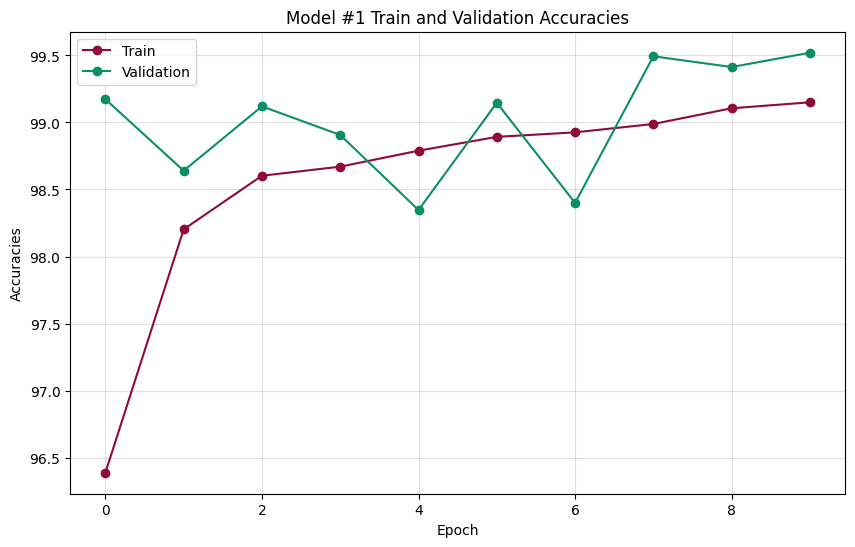

In [27]:
plt.figure(figsize=(10,6))
plt.plot(train_accuracies,marker="o",color="#8F0C35")
plt.plot(val_accuracies,marker="o",color="#0C8F66")
plt.title("Model #1 Train and Validation Accuracies")
plt.xlabel("Epoch")
plt.ylabel("Accuracies")
plt.legend(["Train","Validation"])
plt.grid(alpha=0.4)
plt.show()

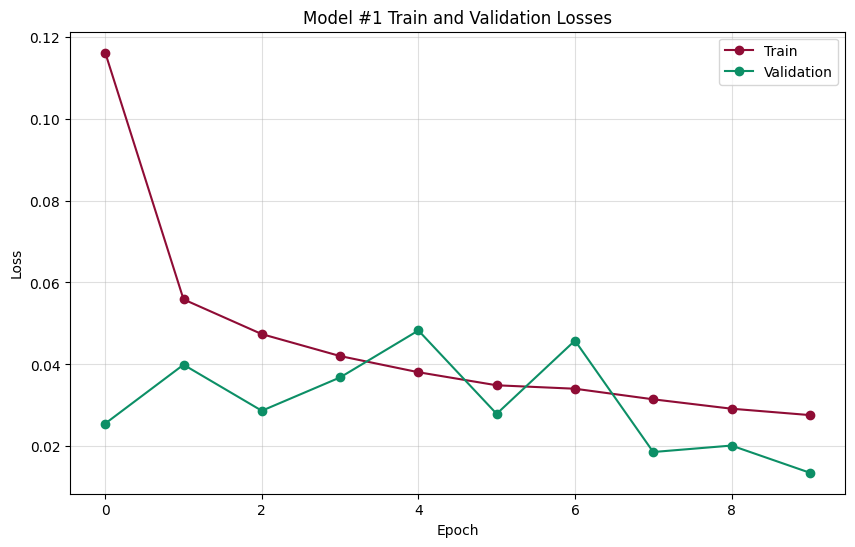

In [28]:
plt.figure(figsize=(10,6))
plt.plot(train_losses,marker="o",color="#8F0C35")
plt.plot(val_losses,marker="o",color="#0C8F66")
plt.title("Model #1 Train and Validation Losses")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend(["Train","Validation"])
plt.grid(alpha=0.4)
plt.show()

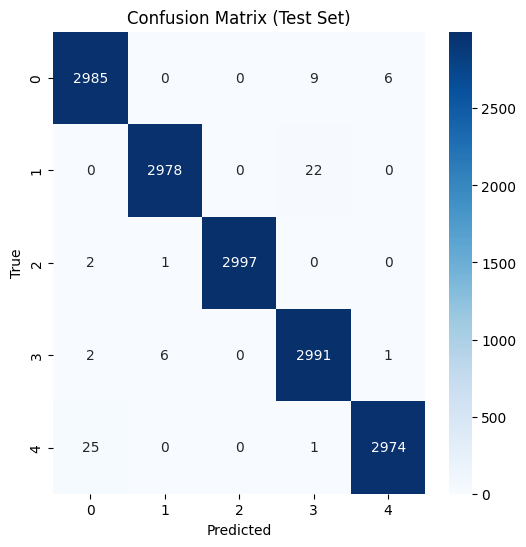

In [29]:
cm = confusion_matrix(all_labels, all_preds)
plt.figure(figsize=(6, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
plt.xlabel("Predicted")
plt.ylabel("True")
plt.title("Confusion Matrix (Test Set)")
plt.show()


In [30]:
print(classification_report(all_labels, all_preds))

              precision    recall  f1-score   support

           0       0.99      0.99      0.99      3000
           1       1.00      0.99      1.00      3000
           2       1.00      1.00      1.00      3000
           3       0.99      1.00      0.99      3000
           4       1.00      0.99      0.99      3000

    accuracy                           0.99     15000
   macro avg       1.00      0.99      1.00     15000
weighted avg       1.00      0.99      1.00     15000



<div style="font-size:17px;margin:12px; padding:16px 20px; border-radius:12px; line-height:1.9;background:#C0D8C4; color:#1b2a22; border-left:5px solid #2ecc71;">These out comes were good we didnt have any overfits and the confusion is showing good numbers.</div>

<div style="background:#0b2a0b; color:#eaffea; padding:20px; text-align:center;
            font-size:30px; border-radius: 0 60px 0 60px; border:2px solid #39ff14;">
  The Model NO. #2 🧠
</div>

<div style="font-size:17px;margin:12px; padding:16px 20px; border-radius:12px; line-height:1.9;background:#C0D8C4; color:#1b2a22; border-left:5px solid #2ecc71;">Preparing everything for nex model just like the previous one.Only differences are image size and layers.</div>

In [31]:
 transform2=transforms.Compose([
     transforms.Resize((128,128)),
     transforms.ToTensor()]
 )

In [32]:
 train_dataset2=RiceDataset(train_df,transform2)

In [33]:
train_loader2=DataLoader(
    train_dataset2,
    batch_size=batchsize,
    shuffle=True
)

In [34]:
transform2=transforms.Compose([
    transforms.Resize((128,128)),
    transforms.ToTensor(),
    transforms.Normalize(mean=mean,std=std),
    ])

train_transform2=transforms.Compose([
    transforms.Resize((128,128)),
    transforms.RandomRotation(30),
    transforms.RandomHorizontalFlip(),
    transforms.RandomVerticalFlip(),
    transforms.ToTensor(),
    transforms.Normalize(mean=mean,std=std)
    ])

In [35]:
train_dataset2=RiceDataset(train_df,train_transform2)
test_dataset2=RiceDataset(test_df,transform2)
val_dataset2=RiceDataset(val_df,transform2)

In [36]:
train_loader2=DataLoader(
    train_dataset2,
    batch_size=batchsize,
    shuffle=True
)

test_loader2=DataLoader(
    test_dataset2,
    batch_size=batchsize,
    shuffle=False
)

val_loader2=DataLoader(
    val_dataset2,
    batch_size=batchsize,
    shuffle=False
)

In [37]:
class Rice_cnn2(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv1=nn.Conv2d(3,32,kernel_size=3)
        self.conv2=nn.Conv2d(32,64,kernel_size=3)
        self.conv3=nn.Conv2d(64,128,kernel_size=3)

        self.relu=nn.ReLU()
        self.pool=nn.MaxPool2d(kernel_size=2,stride=2)
        self.flatten=nn.Flatten()
        self.fc = nn.Linear(25088, 5)
    def forward(self,x):
        x=self.conv1(x)
        x=self.relu(x)
        x=self.pool(x)

        x=self.conv2(x)
        x=self.relu(x)
        x=self.pool(x)

        x=self.conv3(x)
        x=self.relu(x)
        x=self.pool(x)

        x=self.flatten(x)

        x=self.fc(x)

        return x

In [38]:
device=cpu_gpu()
model2=Rice_cnn2().to(device)

In [39]:
opt2=torch.optim.Adam(
    model2.parameters(),
    lr=0.001)

In [40]:
train_losses2 = []
val_losses2 = []
train_accuracies2 = []
val_accuracies2 = []

for epoch in range(epochs):

    model2.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in train_loader2:

        images = images.to(device)
        labels = labels.to(device)

        opt2.zero_grad()

        outputs = model2(images)
        loss = criterion(outputs, labels)

        loss.backward()
        opt2.step()

        running_loss += loss.item()

        _, predicted = torch.max(outputs, 1)

        total += labels.size(0)
        correct += (predicted == labels).sum().item()

    epoch_loss = running_loss / len(train_loader2)
    epoch_acc = 100 * correct / total

    train_losses2.append(epoch_loss)
    train_accuracies2.append(epoch_acc)

    model2.eval()

    val_running_loss = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():

        for images, labels in val_loader2:

            images = images.to(device)
            labels = labels.to(device)

            outputs = model2(images)
            loss = criterion(outputs, labels)

            val_running_loss += loss.item()

            _, predicted = torch.max(outputs, 1)

            val_total += labels.size(0)
            val_correct += (predicted == labels).sum().item()

    val_loss = val_running_loss / len(val_loader2)
    val_acc= 100 * val_correct / val_total

    val_losses2.append(val_loss)
    val_accuracies2.append(val_acc)

    print(f"Epoch [{epoch+1}/{epochs}] "
          f"Train Loss: {epoch_loss:.4f} "
          f"Train Accuracy: {epoch_acc:.2f}% "
          f"Val Loss: {val_loss:.4f} "
          f"Val Accuracy: {val_acc:.2f}%")

Epoch [1/10] Train Loss: 0.0958 Train Accuracy: 96.79% Val Loss: 0.0285 Val Accuracy: 98.99%
Epoch [2/10] Train Loss: 0.0344 Train Accuracy: 98.94% Val Loss: 0.0128 Val Accuracy: 99.63%
Epoch [3/10] Train Loss: 0.0281 Train Accuracy: 99.18% Val Loss: 0.0196 Val Accuracy: 99.44%
Epoch [4/10] Train Loss: 0.0242 Train Accuracy: 99.26% Val Loss: 0.0107 Val Accuracy: 99.76%
Epoch [5/10] Train Loss: 0.0221 Train Accuracy: 99.31% Val Loss: 0.0126 Val Accuracy: 99.60%
Epoch [6/10] Train Loss: 0.0209 Train Accuracy: 99.37% Val Loss: 0.0217 Val Accuracy: 99.31%
Epoch [7/10] Train Loss: 0.0206 Train Accuracy: 99.36% Val Loss: 0.0101 Val Accuracy: 99.63%
Epoch [8/10] Train Loss: 0.0185 Train Accuracy: 99.47% Val Loss: 0.0204 Val Accuracy: 99.28%
Epoch [9/10] Train Loss: 0.0174 Train Accuracy: 99.48% Val Loss: 0.0134 Val Accuracy: 99.65%
Epoch [10/10] Train Loss: 0.0199 Train Accuracy: 99.41% Val Loss: 0.0072 Val Accuracy: 99.84%


In [41]:
model2.eval()

all_preds2 = []
all_labels2 = []
test_running_loss2 = 0.0

with torch.no_grad():
    for images, labels in test_loader2:
        images = images.to(device)
        labels = labels.to(device)

        outputs = model2(images)
        loss = criterion(outputs, labels)
        test_running_loss2 += loss.item()

        _, predicted = torch.max(outputs, 1)
        all_preds2.extend(predicted.cpu().numpy())
        all_labels2.extend(labels.cpu().numpy())

test_loss2 = test_running_loss2 / len(test_loader2)
test_acc2 = 100 * sum(p == l for p, l in zip(all_preds2, all_labels2)) / len(all_labels2)
print(f"Test Loss: {test_loss2:.4f} | Test Accuracy: {test_acc2:.2f}%")

Test Loss: 0.0099 | Test Accuracy: 99.68%


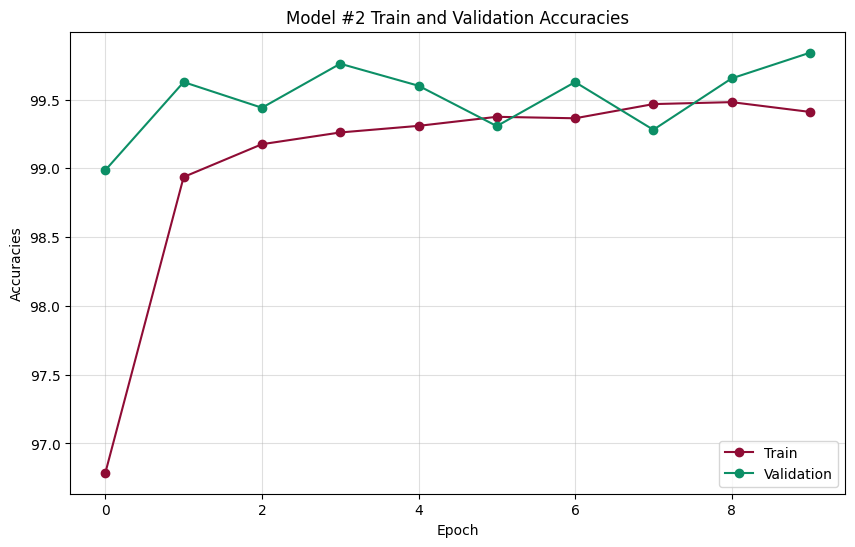

In [42]:
plt.figure(figsize=(10,6))
plt.plot(train_accuracies2,marker="o",color="#8F0C35")
plt.plot(val_accuracies2,marker="o",color="#0C8F66")
plt.title("Model #2 Train and Validation Accuracies")
plt.xlabel("Epoch")
plt.ylabel("Accuracies")
plt.legend(["Train","Validation"])
plt.grid(alpha=0.4)
plt.show()

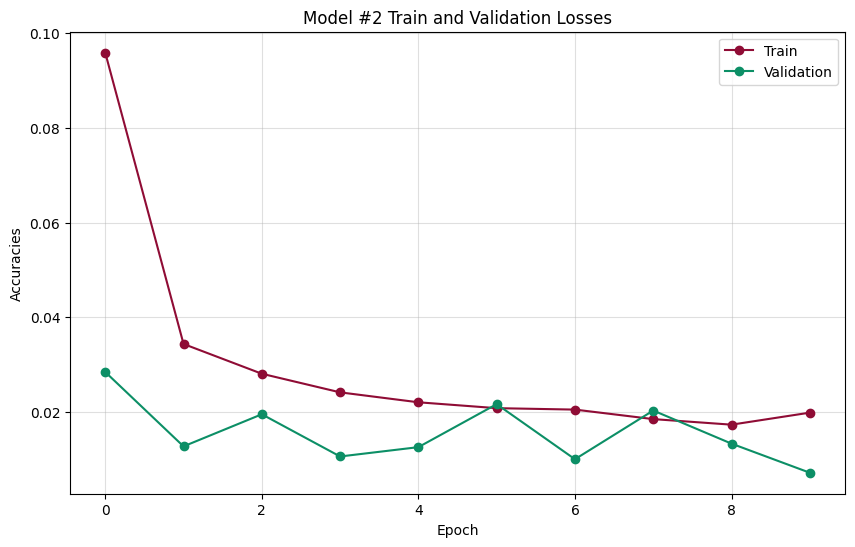

In [43]:
plt.figure(figsize=(10,6))
plt.plot(train_losses2,marker="o",color="#8F0C35")
plt.plot(val_losses2,marker="o",color="#0C8F66")
plt.title("Model #2 Train and Validation Losses")
plt.xlabel("Epoch")
plt.ylabel("Accuracies")
plt.legend(["Train","Validation"])
plt.grid(alpha=0.4)
plt.show()

In [44]:
print(classification_report(all_labels2, all_preds2))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00      3000
           1       1.00      1.00      1.00      3000
           2       1.00      1.00      1.00      3000
           3       1.00      0.99      0.99      3000
           4       1.00      1.00      1.00      3000

    accuracy                           1.00     15000
   macro avg       1.00      1.00      1.00     15000
weighted avg       1.00      1.00      1.00     15000



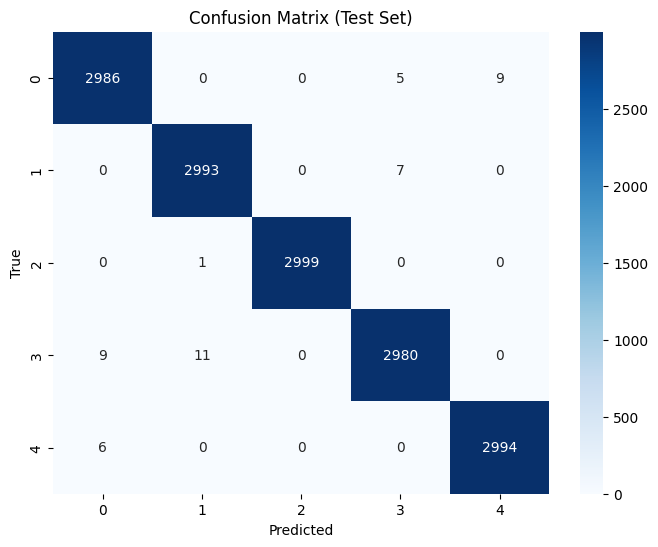

In [45]:
cm2 = confusion_matrix(all_labels2, all_preds2)
plt.figure(figsize=(8, 6))
sns.heatmap(cm2, annot=True, fmt="d", cmap="Blues")
plt.xlabel("Predicted")
plt.ylabel("True")
plt.title("Confusion Matrix (Test Set)")
plt.show()

In [46]:
torch.save(model.state_dict(),"model1_best_acc.pth")
torch.save(model2.state_dict(),"model2_best_acc.pth")
files.download("model1_best_acc.pth")
files.download("model2_best_acc.pth")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<div style="font-size:17px;margin:12px; padding:16px 20px; border-radius:12px; line-height:1.9;background:#C0D8C4; color:#1b2a22; border-left:5px solid #2ecc71;">This is our Best outcome the numbers on confusion matrix are greate better than the tf model th sum of fp and fn hase reduced to 78 (with tf it was 83).The best out come was for epoch 3. </div>

<div style="text-align: center;">
  <a href="https://github.com/amir-hlj">
    <img src="https://cdn.jsdelivr.net/npm/simple-icons@v11/icons/github.svg"
         width="60">
  </a>
  <br>
  <b>Visit My GitHub Profile</b>
</div>